# Nonlinear benchmarks: equations, evidence and boundaries

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/notebook.ipynb)

This notebook accompanies Kroll & Schulte (2014), [DOI](https://doi.org/10.1016/j.asoc.2014.08.034). It runs the locally specified models and inspects the external-model status. Synthetic short checks are not a reproduction of all published control results. Read [the section-by-section guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md), [case studies](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/CASE_STUDIES.md), and [original equipment diagrams](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md).


## Visual reading guide

![Inverted pendulum equipment](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/03-pendulum.png)

The actuator force moves the cart; the pendulum angle and cart displacement are distinct states. Read each model's state/input convention before interpreting a trace. This figure describes equipment, not a successful control experiment.

![Three-tank equipment](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/07-three-tanks.png)

The three-tank balance in the article closes the nominal drains: sustained positive pumping accumulates liquid. A steady tracking study therefore needs an explicitly declared outlet extension. [All equipment diagrams](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md) cover the other processes; [unit-by-unit applications](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/README.md) connect this inventory with the nine course methods.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")
sys.path.insert(0, str(ROOT / "benchmarks"))
import json
import numpy as np
from intelligent_control import benchmarks as b


Environment ready


## Two artificial identification problems

Equation (30) maps two output lags and one input into the next SISO output. Equation (31) is a two-input/two-output recurrence. Training inputs are independent uniform signals; validation uses sine/cosine signals with a period of 25 samples. The paper uses 100000 training samples; the quick check below uses 1000. Never randomly mix adjacent time-series observations across train/test sets.

In [2]:
u_train, y_train = b.artificial_data(1000, 'siso', 'train', seed=2014)
u_test, y_test = b.artificial_data(250, 'siso', 'validation')
assert y_train.shape == (1001, 1)
print('Training range:', u_train.min(), u_train.max())
print('First transition:', y_train[0,0], u_train[0,0], y_train[1,0])

Training range: -1.9899601022954099 1.9974046371740557
First transition: 0.0 1.6743361124586578 1.6743361124586578


## Conservation is an independent numerical check

The printed three-tank equation has all drains closed. Internal transfer flows cancel when the three balances are added. The stored-volume derivative must equal the two pump flows; sustained positive pumping therefore cannot have a steady state.

In [3]:
h = np.array([0.4, 0.2, 0.3]); q = np.array([3e-5, 2e-5])
dh = b.three_tank_rhs(0, h, q)
assert np.isclose(0.0154*dh.sum(), q.sum(), rtol=1e-12)
print('dV/dt:', 0.0154*dh.sum(), 'm³/s')

dV/dt: 5e-05 m³/s


## Audit the bioreactor setpoint

For a nonwashout equilibrium, `(1-C2) exp(C2/Γ)=u` and `C1=C2(1+β-C2)/(1+β)`. With Γ=0.4, β=0.02 and u=0.769, these equations disagree with the biomass value in the article's prose. The calculation below preserves the equations and exposes the discrepancy. One controller hold is 50 Euler substeps, not a single 0.01 step.

In [4]:
from scipy.optimize import brentq
c2 = brentq(lambda s: (1-s)*np.exp(s/0.4)-0.769, 0.8, 1)
c1 = c2*(1.02-c2)/1.02
print('Computed equilibrium:', c1, c2)
print('Equation residual:', b.bioreactor_rhs(0,[c1,c2],0.769))
print('Residual with prose biomass:', b.bioreactor_rhs(0,[0.1236837,c2],0.769))
assert np.max(np.abs(b.bioreactor_rhs(0,[c1,c2],0.769))) < 1e-10

Computed equilibrium: 0.08729754781771586 0.9235897740828826
Equation residual: [3.19189120e-16 3.33066907e-15]
Residual with prose biomass: [4.30211422e-16 2.96032602e-01]


## Throttle model architecture without invented measured data

The `LocalARX` class provides eight local affine autoregressive predictors. Its partition features are output increment and previous input. Crisp and soft blending are separate choices. The following test uses an explicitly synthetic linear process to check the implementation. The official 10000/2500-sample throttle records are still required for a benchmark score.

In [5]:
rng = np.random.default_rng(2014)
u = rng.normal(size=600); y = np.zeros(600)
for k in range(599):
    y[k+1] = 0.5*y[k] + 0.3*u[k]
for mode in ['crisp','soft']:
    model = b.LocalARX(mode=mode).fit(u[:400],y[:400])
    prediction = model.predict(u[400:],y[400:],recursive=True)
    print(mode, 'synthetic free-run RMSE:', np.sqrt(np.mean((prediction[2:]-y[402:])**2)))

crisp synthetic free-run RMSE: 1.0298062816437973e-09
soft synthetic free-run RMSE: 4.550033401041642e-10


## Run the model checks

The runner simulates the pendulum, closed-drain tanks, sampled bioreactor, CSTR, full 82-state Column A with level loops, and the reduced nine-state wind model with the documented later ROSCO map. It evaluates the pneumatic/hydrostatic components with their qualification and reports preserved external evidence separately, including its path and hash. This notebook does not rerun OpenFAST, ALSTOM or Tennessee Eastman.
Separate [pneumatic](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/PNEUMATIC_AUDIT.md) and [hydrostatic SI](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/HYDROSTATIC_SOURCE_REVIEW.md) variants passed Python, MATLAB/Octave and native Simulink comparisons. Their experimental calibration remains unresolved. The [throttle pipeline](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/THROTTLE_RECOVERY.md) is verified with synthetic fixtures; original measurements remain unavailable.


{
  "output": "benchmarks/results",
  "experiments": 15,
  "column_residual": 3.863576125695545e-13,
  "tank_volume_residual": 4.336808689942018e-19
}


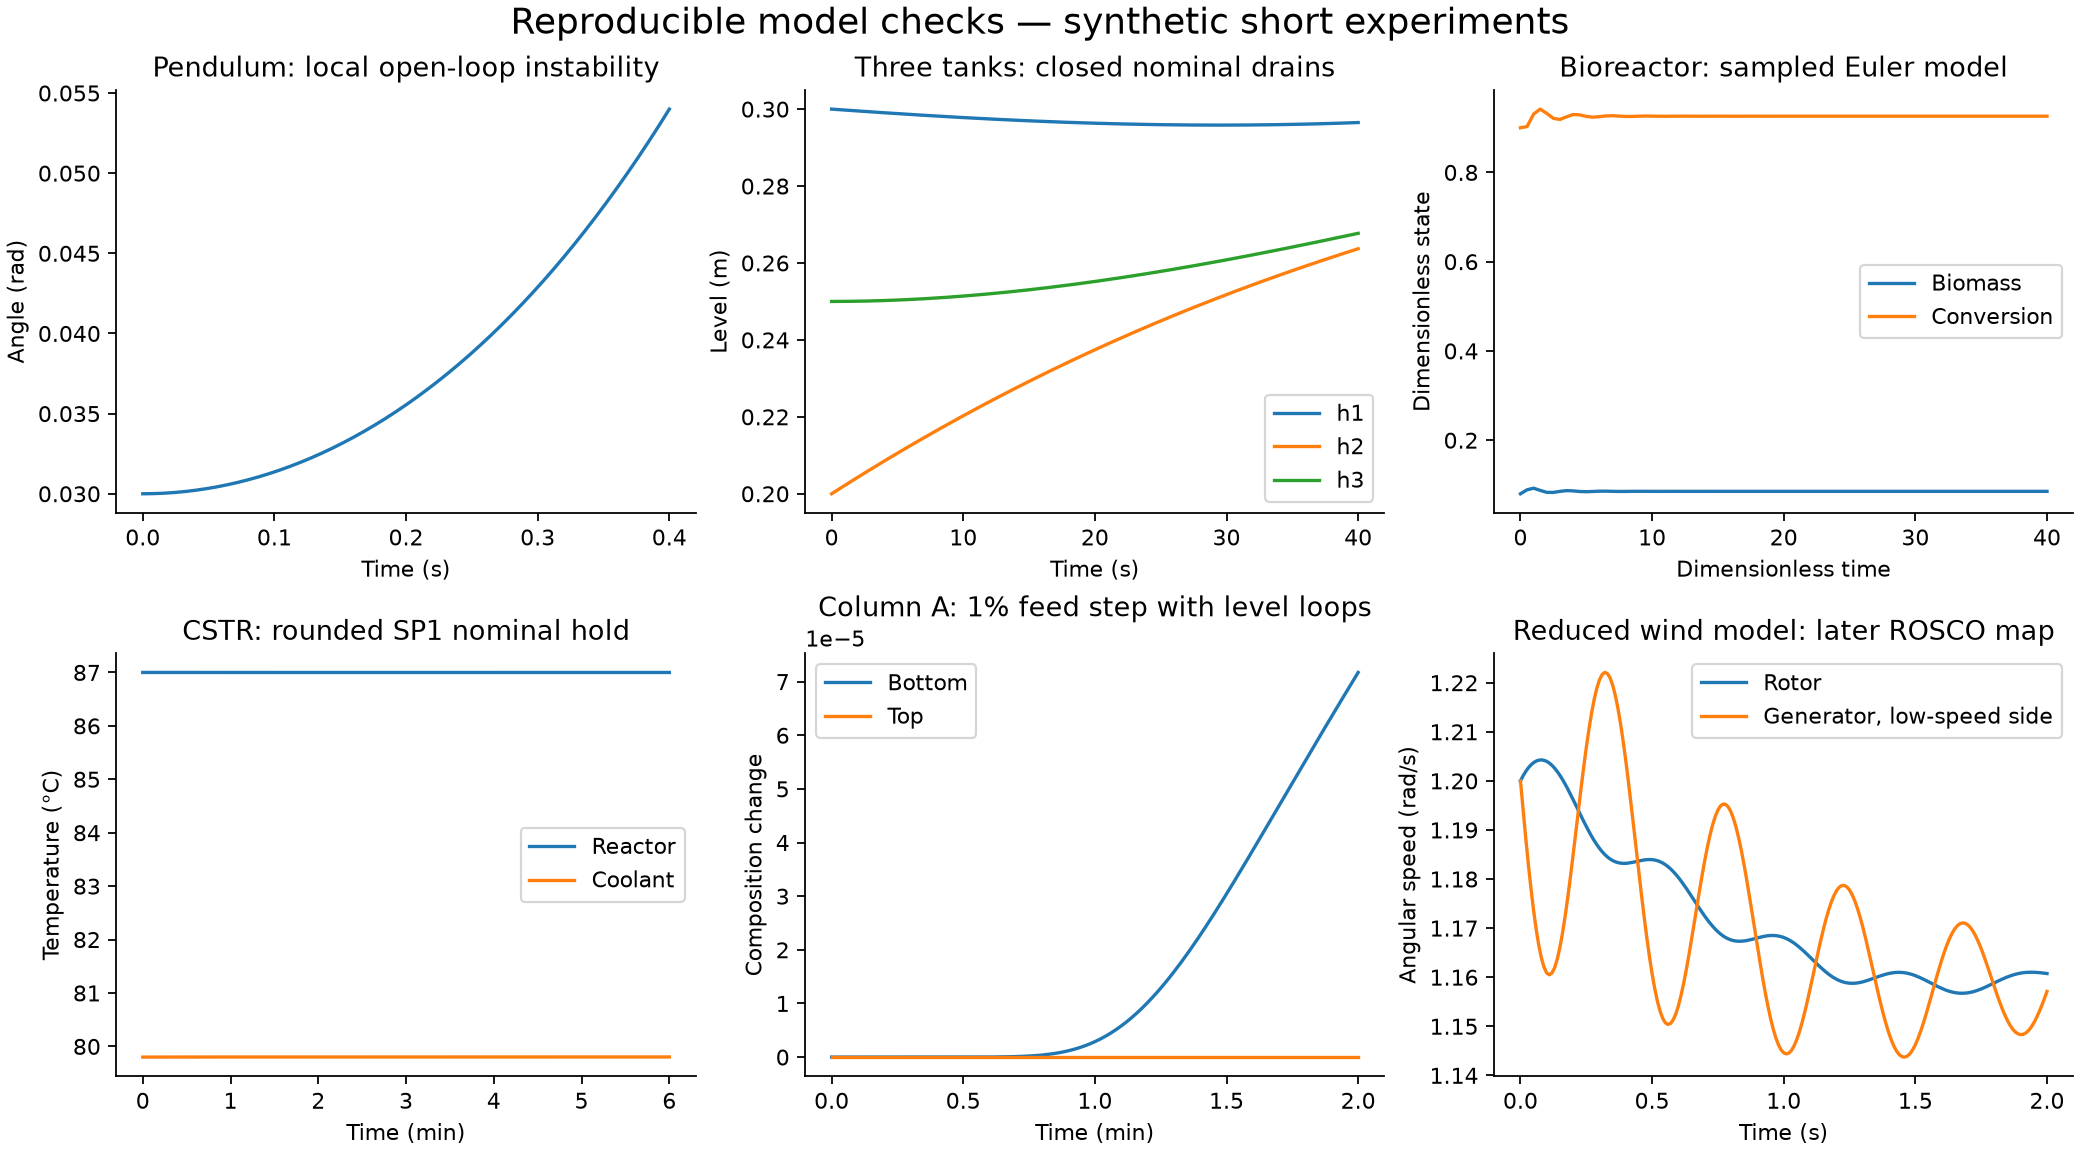

In [6]:
from run_benchmarks import main
summary = main()
from IPython.display import Image, display
display(Image(filename=str(ROOT/'benchmarks/results/benchmark_overview.png')))

The saved evidence records an official OpenFAST v5.0.0 run and baseline comparison, three native revised Tennessee Eastman cases, and eleven actual ALSTOM PI cases plus two solver-sensitivity runs. The [ALSTOM results](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/ALSTOM_RESULTS.md) retain performance violations and nominal drift; successful integration is not successful control. The following cell reads preserved records without rerunning these simulators. Source hashes, runtime requirements and experiment limits are in [the external guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/EXTERNAL_MODELS.md).


In [7]:
for name, record in summary['experiments'].items():
    if 'status' in record:
        print(name, ':', record['status'])
    if record.get('evidence_state') == 'preserved_passed_record':
        print('  Preserved evidence:', record['evidence_path'])
        print('  SHA-256:', record['evidence_sha256'])
    if 'source_inspection' in record:
        print('  Source inspection:', record['source_inspection']['evidence_path'])


pneumatic : balance/closure evaluation, not canonical valve simulation
hydrostatic : literal transcription only; primary-source clarification and separate SI variant documented
wind_fast : preserved OpenFAST execution and baseline comparison passed; not rerun by this command
  Preserved evidence: benchmarks/results/openfast-validation.json
  SHA-256: 8b7bdcf8930c3c6a41acb4c178f34f680f67bc77a0b9edd408eed7bd3169952c
gasifier : preserved native ALSTOM integration/input checks passed; inspect reported control violations; not rerun by this command
  Preserved evidence: benchmarks/results/alstom-native/validation.json
  SHA-256: 3c52843a8a503f4df069446d052d50f91b06925f23a7bf524bd0f70a1dd16bb9
  Source inspection: benchmarks/results/alstom-source-inspection.json
tennessee_eastman : preserved official revised TE nominal, IDV1 and IDV4 executions passed; not rerun by this command
  Preserved evidence: benchmarks/results/te-native/validation.json
  SHA-256: e9b72411e51548cff4554a81087ff322f34f6a